In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import ComplementNB
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

In [10]:
DATA_PATH = r'E:\Desktop\CodePro - Peguin\The hatch\The-hatch---ch3\Datasets' + '\\'

reviews = pd.read_csv(DATA_PATH + 'olist_order_reviews_dataset.csv')

print(f"Reviews cargadas: {reviews.shape}")
print(reviews['review_score'].value_counts().sort_index())

Reviews cargadas: (99224, 7)
review_score
1    11424
2     3151
3     8179
4    19142
5    57328
Name: count, dtype: int64


In [11]:
# el 3 es muy ambiguo, lo saco
df = reviews[reviews['review_score'] != 3].copy()

# Etiqueta binaria
df['sentimiento'] = (df['review_score'] >= 4).astype(int)  # 1=positivo, 0=negativo

# junto título y comentario en un solo campo de texto
df['texto'] = df['review_comment_title'].fillna('') + ' ' + df['review_comment_message'].fillna('')
df['texto'] = df['texto'].str.strip()

# Eliminar filas sin texto
df = df[df['texto'] != '']

print(f"Reviews con texto: {len(df)}")
print(f"Positivas: {df['sentimiento'].sum()} | Negativas: {(df['sentimiento']==0).sum()}")

Reviews con texto: 39044
Positivas: 28050 | Negativas: 10994


In [12]:
# acá uso split aleatorio, no hace falta ordenar por fecha para sentimientos
X_train, X_test, y_train, y_test = train_test_split(
    df['texto'], df['sentimiento'], test_size=0.2, random_state=42
)

# stopwords en portugués — las más comunes que no aportan significado
stopwords_pt = [
    'de', 'a', 'o', 'que', 'e', 'do', 'da', 'em', 'um', 'para',
    'com', 'uma', 'os', 'no', 'se', 'na', 'por', 'mais', 'as',
    'dos', 'como', 'mas', 'ao', 'ele', 'das', 'seu', 'sua', 'ou',
    'quando', 'muito', 'nos', 'já', 'eu', 'também', 'só', 'pelo',
    'pela', 'até', 'isso', 'ela', 'entre', 'depois', 'sem', 'mesmo'
]
# no incluyo "não" en las stopwords porque cambia el significado
# "bom" vs "não bom" son cosas muy distintas

vectorizer = TfidfVectorizer(
    max_features=5000,
    stop_words=stopwords_pt,
    ngram_range=(1, 2)
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf  = vectorizer.transform(X_test)

print(f"Train: {X_train_tfidf.shape} | Test: {X_test_tfidf.shape}")

Train: (31235, 5000) | Test: (7809, 5000)


In [13]:
modelos = {
    'ComplementNB':        ComplementNB(),   # vi que es mejor que MultinomialNB para clases desbalanceadas
    'LinearSVC':           LinearSVC(class_weight='balanced', max_iter=2000),
    'Logistic Regression': LogisticRegression(class_weight='balanced', max_iter=1000)
}

resultados = {}
for nombre, modelo in modelos.items():
    modelo.fit(X_train_tfidf, y_train)
    y_pred = modelo.predict(X_test_tfidf)
    report = classification_report(y_test, y_pred, output_dict=True)
    resultados[nombre] = {
        'Accuracy':        report['accuracy'],
        'Recall Negativo': report['0']['recall'],
        'Recall Positivo': report['1']['recall'],
        'F1 Negativo':     report['0']['f1-score']
    }

print(f"{'Modelo':<25} {'Accuracy':>10} {'Recall Neg':>12} {'Recall Pos':>12}")
print("-" * 61)
for nombre, m in resultados.items():
    print(f"{nombre:<25} {m['Accuracy']:>10.4f} {m['Recall Negativo']:>12.4f} {m['Recall Positivo']:>12.4f}")

Modelo                      Accuracy   Recall Neg   Recall Pos
-------------------------------------------------------------
ComplementNB                  0.9065       0.9601       0.8860
LinearSVC                     0.9328       0.9305       0.9336
Logistic Regression           0.9300       0.9481       0.9230


              precision    recall  f1-score   support

    Negativo       0.82      0.95      0.88      2158
    Positivo       0.98      0.92      0.95      5651

    accuracy                           0.93      7809
   macro avg       0.90      0.94      0.92      7809
weighted avg       0.94      0.93      0.93      7809


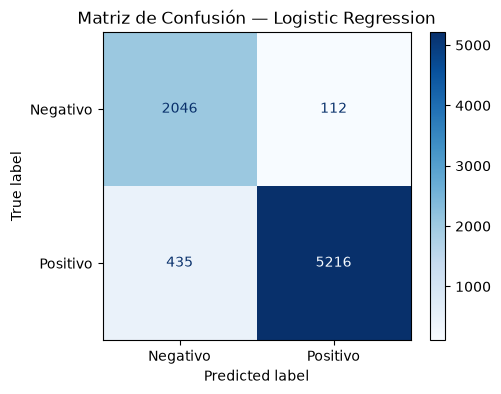

In [6]:
# me quedo con LR — pierde un poco de accuracy pero detecta mejor los negativos
mejor_modelo = modelos['Logistic Regression']
y_pred_final = mejor_modelo.predict(X_test_tfidf)

from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
print(classification_report(y_test, y_pred_final, target_names=['Negativo', 'Positivo']))

cm = confusion_matrix(y_test, y_pred_final)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Negativo', 'Positivo'])
disp.plot(cmap='Blues')
plt.title('Matriz de Confusión — Logistic Regression')
plt.show()

## Conclusiones

| Modelo | Accuracy | Recall Negativo | Recall Positivo |
|---|---|---|---|
| ComplementNB | 90.7% | 96.0% | 88.6% |
| LinearSVC | 93.3% | 93.0% | 93.4% |
| **Logistic Regression** | **93.0%** | **94.8%** | **92.3%** |

**Lo que aprendí:**
- TF-IDF con bigramas ayuda porque "não gostei" es muy diferente a "gostei"
- El dataset tiene muchos más positivos que negativos (28k vs 11k), por eso usé class_weight balanced
- Elegí Logistic Regression porque detecta mejor los negativos aunque LinearSVC tiene más accuracy general